In [1]:
import numpy as np
from scipy.io import loadmat
import ipywidgets as widgets
from scipy.signal import resample
import os 

import matplotlib.pyplot as plt
from ipywidgets import IntRangeSlider, VBox, HBox, Output,Label
from IPython.display import display, Audio
from ipyfilechooser import FileChooser
import Funciones as Funciones
import scipy.signal as sig
from math import gcd
%matplotlib widget
%config InlineBackend.figure_format = 'svg'

In [2]:
FC = FileChooser("G:/Mi unidad/Facultad/Beca CIN/NNMF-GIF/Repositorio AC3E")
FC.layout = widgets.Layout(width='1000px')
display(FC)

FileChooser(path='G:\Mi unidad\Facultad\Beca CIN\NNMF-GIF\Repositorio AC3E', filename='', title='', show_hidde…

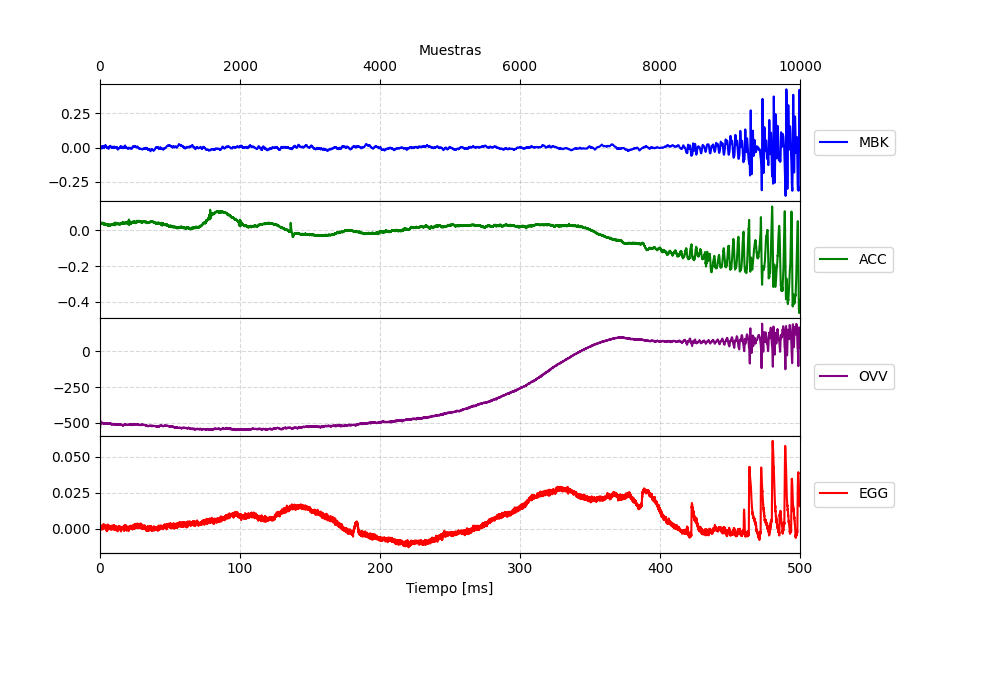

In [3]:
mat_contents = loadmat(FC.selected, squeeze_me=True)
fs = 20000
min_range = 600

MBK = mat_contents["MBK"]["data"]
MBK_ = (np.array(MBK)/ np.max(np.abs(MBK))).astype(np.float32)
ACC = mat_contents["ACC"]["data"][()]
OVV = mat_contents["OVV"]["data"][()]
EGG = mat_contents["EGG"]["data"][()]

def MuestrasTiempo(muestras):
    return muestras * 1000 / fs


def TiempoMuestras(tiempo):
    return np.round(tiempo * fs / 1000)


fig, ax = plt.subplots(4, 1, figsize=(10, 7))
fig.canvas.header_visible = False
fig.subplots_adjust(left=0.1, right=0.80)
audio_out = Output(layout=widgets.Layout(width="75%"))

n0 = 0
n1 = 0
def f(x):
    global n0
    global n1
    if x[1] - x[0] > min_range:
        n0 = x[0]
        n1 = x[1]
        for a in ax:
            a.clear()

        muestras = np.arange(x[0], x[1])

        señal_MBK = MBK_[x[0] : x[1]]
        ax[0].plot(muestras, señal_MBK, color="blue", label="MBK")
        ax[0].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), borderaxespad=0.0)
        ax[0].grid(True, linestyle="dashed", color="gray", alpha=0.3, which="both")
        ax[0].set_xlim(x[0], x[1])
        #sec = ax[0].secondary_xaxis("top", functions=(MuestrasTiempo, TiempoMuestras))
        #sec.set_xlabel("Tiempo [ms]")
        # Eje superior: muestras
        ax[0].set_xlabel("Muestras")    # etiqueta arriba
        ax[0].xaxis.set_label_position("top") 
        ax[0].tick_params(axis='x', which='both', bottom=False, labelbottom=False, top=True, labeltop=True)


        señal_ACC = ACC[x[0] : x[1]]
        ax[1].plot(muestras, señal_ACC, color="green", label="ACC")
        ax[1].grid(True, linestyle="dashed", color="gray", alpha=0.3, which="both")
        ax[1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), borderaxespad=0.0)
        ax[1].set_xlim(x[0], x[1])
        ax[1].tick_params(axis='x', which='both',labelbottom=False)
        pos1 = ax[0].get_position()
        pos2 = ax[1].get_position()
        ax[1].set_position([pos2.x0, pos1.y0 - pos2.height, pos2.width, pos2.height])

        señal_OVV = OVV[x[0] : x[1]]
        ax[2].plot(muestras, señal_OVV, color="purple", label="OVV")
        ax[2].grid(True, linestyle="dashed", color="gray", alpha=0.3, which="both")
        ax[2].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), borderaxespad=0.0)
        ax[2].grid(True, linestyle="dashed", color="gray", alpha=0.3, which="both")
        ax[2].set_xlim(x[0], x[1])
        ax[2].tick_params(axis='x', which='both',labelbottom=False)
        pos3 = ax[1].get_position()
        pos4 = ax[2].get_position()
        ax[2].set_position([pos4.x0, pos3.y0 - pos4.height, pos4.width, pos4.height])

        señal_EGG = EGG[x[0] : x[1]]
        ax[3].plot(muestras, señal_EGG, color="red", label="EGG")

        # Fijar límites del eje principal
        ax[3].set_xlim(x[0], x[1])

        # Ocultar ticks y etiqueta del eje principal inferior
        ax[3].tick_params(axis='x', which='both', bottom=False, labelbottom=False)

        # Eje secundario inferior: tiempo en ms
        sec = ax[3].secondary_xaxis("bottom", functions=(MuestrasTiempo, TiempoMuestras))
        sec.set_xlabel("Tiempo [ms]")
        ax[3].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), borderaxespad=0.0)
        ax[3].grid(True, linestyle="dashed", color="gray", alpha=0.3, which="both")
        pos5 = ax[2].get_position()
        pos6 = ax[3].get_position()
        ax[3].set_position([pos6.x0, pos5.y0 - pos6.height, pos6.width, pos6.height])

        audio_out.clear_output()
        fig.canvas.draw()

        with audio_out:
            display(Audio(señal_MBK, rate=fs, autoplay=True))


slider = IntRangeSlider(
    value=[0, 10000],
    min=0,
    max=len(MBK_),
    step=1,
    description="Muestras:",
    continuous_update=False,
    orientation="horizontal",
    readout=True,
    readout_format="d",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="70%"),
)
# Label para mostrar duración en ms
duration_label = Label()

def update_duration(change):
    x0, x1 = change['new']
    if x1 - x0 > min_range:
        dur_ms = (x1 - x0) * 1000 / fs
        duration_label.value = f"  |   Duración: {dur_ms:.1f} ms"

# Conectar el slider al label
slider.observe(update_duration, names='value')

# Inicializar el label con el valor inicial
update_duration({'new': slider.value})

out = widgets.interactive_output(f, {'x': slider})

ui = VBox([
    out,
    HBox([slider, duration_label], layout=widgets.Layout(width='100%')),
    HBox([audio_out], layout=widgets.Layout(width='100%'))
])

display(ui);

In [9]:
fs   = 20000
fs_r = 8000
OVV_original  = OVV[n0 : n1]
t_original = np.arange(len(OVV_original)) *(1000/ fs)
fft_ovv_oringinal, frec_ovv_original = Funciones.FFT(OVV_original,fs)

n_samples_resampled = int(len(OVV_original) * fs_r / fs)
OVV_resample = sig.resample(OVV_original, n_samples_resampled)

t_resample = np.arange(len(OVV_resample))* (1000/ fs_r)

fft_ovv_resample, frec_ovv_resample= Funciones.FFT(OVV_resample,fs_r)
up = fs_r
down = fs
g = gcd(up, down)
up = up//g
down = down // g
OVV_resample_poly  = sig.resample_poly(OVV_original, up, down)
fft_ovv_resample_poly, frec_ovv_resample_poly= Funciones.FFT(OVV_resample_poly,fs_r)
t_resample_poly = np.arange(len(OVV_resample_poly))* (1000/ fs_r)

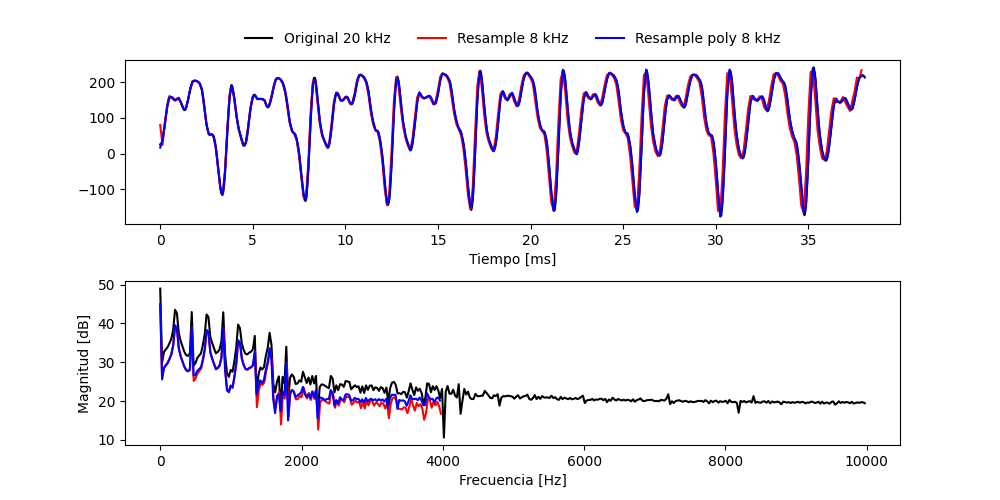

In [10]:
fig, ax1 = plt.subplots(2, 1, figsize=(10, 5))
fig.canvas.header_visible = False
fig.subplots_adjust(hspace=0.35)

ax1[0].plot(t_original, OVV_original, color='k', label='Original 20 kHz')
ax1[0].plot(t_resample, OVV_resample, color='r', label='Resample 8 kHz')
ax1[0].plot(t_resample_poly, OVV_resample_poly, color='b', label='Resample poly 8 kHz')
ax1[0].set_xlabel("Tiempo [ms]")

handles, labels = ax1[0].get_legend_handles_labels()
ax1[0].legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.25), ncol=3, frameon=False)

ax1[1].plot(frec_ovv_original, 10*np.log10(abs(fft_ovv_oringinal)), color='k')
ax1[1].plot(frec_ovv_resample, 10*np.log10(abs(fft_ovv_resample)), color='r')
ax1[1].plot(frec_ovv_resample_poly, 10*np.log10(abs(fft_ovv_resample_poly)), color='b')
ax1[1].set_xlabel("Frecuencia [Hz]")
ax1[1].set_ylabel("Magnitud [dB]");
